# Loading required packages

In [1]:
import pandas as pd
import glob
import os
import ast
import re
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, mean_absolute_error, mean_absolute_percentage_error
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder,PolynomialFeatures, TargetEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor

# Loading datasets

In [2]:
all_files=glob.glob(os.path.join("./data", "*.csv"))
city_data = {}
for filename in all_files:
    name = os.path.basename(filename).replace(".csv", "")
    city_data[name] = pd.read_csv(filename, low_memory=False)

In [3]:
for i in city_data.keys():
    print(i , city_data[i].shape)

gurgaon_10k (10704, 67)
hyderabad (9487, 55)
kolkata (8797, 35)
mumbai (9514, 55)


In [4]:
for city_name, df in city_data.items():
    df["Source_City"] = city_name
master_df = pd.concat(city_data.values(), axis=0, join="outer", ignore_index=True)
master_df.head()

,PROP_ID,PHOTO_URL,MEDIUM_PHOTO_URL,PREFERENCE,DESCRIPTION,PROPERTY_TYPE,CITY,LOCALITY,TRANSACT_TYPE,OWNTYPE,...,ALT_TAG,PRODUCT_TYPE,PROPERTY_TYPE__U,SECONDARY_AREA,VALUE_LABEL,REGISTER_DATE__U,REGISTERED_DAYS,PRIMARY_TAGS,SUPER_AREA,SUPERAREA_UNIT
0,O71585872,https://mediacdn.99acres.com/media1/22409/13/4...,https://mediacdn.99acres.com/media1/22409/13/4...,S,4 bhk flat for resale in alpha corp gurgaon one,Residential Apartment,Gurgaon,Sector 84 Gurgaon,1.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,T71585466,https://mediacdn.99acres.com/media1/22425/6/44...,https://mediacdn.99acres.com/media1/22425/6/44...,S,"Explore dlf ultima, an upscale ready-To-Move h...",Residential Apartment,Gurgaon,Sector 81 Gurgaon,1.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,D71549524,https://mediacdn.99acres.com/media1/22386/13/4...,https://mediacdn.99acres.com/media1/22386/13/4...,R,A 3 bhk flat for rent in sector 66 gurgaon clo...,Residential Apartment,Gurgaon,Sector 66 Gurgaon,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,I71493958,https://mediacdn.99acres.com/media1/22353/14/4...,https://mediacdn.99acres.com/media1/22353/14/4...,S,Looking for a 3 bhk property for purchase in g...,Residential Apartment,Gurgaon,Sector 112 Gurgaon,1.0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,H71479412,https://mediacdn.99acres.com/media1/22352/4/44...,https://mediacdn.99acres.com/media1/22352/4/44...,R,This 4 bhk flat in sector 104 gurgaon is avail...,Residential Apartment,Gurgaon,Sector 104 Gurgaon,NaN,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Data preprocessing
- Here we are treating null values
- Treating the buckets and make them as numerical values.

In [5]:
# Calculate null percentage per column
null_counts = master_df.isnull().mean() * 100

# Retain columns with less than 60% missing data
usable_columns = null_counts[null_counts < 60].index.tolist()

In [6]:
# Eliminating columns with null data more than 60 %
master_df = master_df[usable_columns]

In [7]:
# Titling every column
master_df.columns = master_df.columns.str.title()

In [8]:
# Using only data of S (Sales) - Removing data of R (Rent) and P (PG)
master_df = master_df[master_df["Preference"] == "S"].copy()
master_df.drop("Preference",axis="columns",inplace=True)

In [9]:
def parse_price(text):
    # Handle missing or empty inputs
    if pd.isna(text) or text == "":
        return np.nan
    text = str(text).lower().replace(',', '').strip()

    # Process price ranges (e.g., '1-2 Cr') by averaging endpoints
    if '-' in text:
        parts = text.split('-')
        p1, p2 = parts[0].strip(), parts[1].strip()
        # Ensure unit propagation for range endpoints
        if not any(unit in p1 for unit in ['cr','l']) and 'cr' in p2: p1 += 'cr'
        elif not any(unit in p1 for unit in ['cr', 'l']) and 'l' in p2: p2 += 'l'

        val1, val2 = parse_price(p1), parse_price(p2)
        return (val1 + val2) / 2 if (val1 is not None and val2 is not None) else (val1 or val2)

    # Extract numeric part
    num_match = re.search(r"(\d+\.?\d*)", text)
    if not num_match: return np.nan
    num = float(num_match.group(1))

    # Apply scaling factors for units
    if "cr" in text: return num * 10000000
    if "l" in text: return num * 100000
    return num

def parse_areas(text):
    # Handle missing or empty inputs
    if pd.isna(text) or text == "":
        return np.nan
    text = str(text).lower().strip().replace(",", "")

    # Process area ranges (e.g., '300-500') by averaging endpoints
    if "-" in text:
        parts = text.split("-")
        val1, val2 = parse_areas(parts[0].strip()), parse_areas(parts[1].strip())
        return (val1 + val2) / 2 if (val1 is not None and val2 is not None) else (val1 or val2)
        
    # Extract numeric area value
    num_search = re.search(r"(\d+\.?\d*)", text)
    return float(num_search.group(1)) if num_search else np.nan

In [10]:
# Applying parse_price and parse_area to Price and Area columns of master_df
master_df["Price"] = master_df["Price"].apply(parse_price)
master_df["Area"] = master_df["Area"].apply(parse_areas)

In [11]:
# Filtering only those rows where Price is not NaN
master_df = master_df[master_df["Price"].isna() != True]

In [12]:
master_df.isnull().sum()

Prop_Id                           0
Description                       0
Property_Type                     0
City                              0
Transact_Type                    21
Owntype                           0
Bedroom_Num                    3518
Balcony_Num                    9640
Price_Per_Unit_Area               0
Furnish                           0
Facing                            0
Age                               0
Floor_Num                      5888
Total_Floor                     618
Features                          0
Register_Date                  7027
Prop_Name                      4534
Min_Price                      7027
Max_Price                      7027
Price_Sqft                        0
Building_Id                    7027
Map_Details                       0
Min_Area_Sqft                  7027
Max_Area_Sqft                  7027
Amenities                      7366
Top_Usps                      17470
Expiry_Date                    7027
Area                        

## Removing unwanted columns

In [13]:
# Removing columns that have more than 50% null values
limit = master_df.shape[0] * 0.5
master_df = master_df.dropna(thresh=limit,axis='columns')

In [14]:
columns_to_remove = [
    'Register Date', 'Building Id', 'Min Area Sqft', 'Expiry Date', 
    'Class_Heading', 'Class_Label', 'Building_Name', 'Society Name', 
    'Prop Name', 'Formatted_Landmark_Details', 'Prop Heading', "City",
    'Secondary Tags', 'Price Sqft', 'Description', 'Price_Per_Unit_Area', 
    'Prop Id', 'Transact Type', 'Min Price', 'Max Price', 
    'Min Area Sqft', 'Max Area Sqft', 'Formatted Landmark Details', 
    'Building Name', 'Prop Id', 'Description', 'Transact_Type', 
    'Price Per Unit Area',"Society_Name","Register_Date","Prop_Heading",
    "Expiry_Date","Building_Id","Secondary_Tags","Price_Sqft","Prop_Name",
    "Min_Price","Max_Area_Sqft","Prop_Id","Min_Area_Sqft","Max_Price","Map_Details"
]
# Drop specified columns; 'errors="ignore"' ensures the code continues if a column is already missing
master_df = master_df.drop(columns_to_remove, axis="columns", errors="ignore")

In [15]:
master_df.rename(columns={"Source_City" : "City"},inplace=True)

In [16]:
# Convert string representations to actual Python dictionaries
loc_df = [ast.literal_eval(row) for row in master_df["Location"]]

# Expand the list of dictionaries into a separate DataFrame
loc_df = pd.DataFrame(loc_df)

# Reset indices to ensure perfect row alignment before merging
master_df = master_df.reset_index(drop=True)
loc_df = loc_df.reset_index(drop=True)

# Concatenate the 'LOCALITY_NAME' column from the location data to the master DataFrame
master_df = pd.concat([master_df, loc_df[["LOCALITY_NAME"]]], axis="columns")

master_df = master_df.drop(columns=["Location"])

In [17]:
# Standardize city names by removing unwanted suffixes
master_df["City"] = master_df["City"].str.replace("gurgaon_10k", "gurgaon")

# Ensure city names are in title case for consistent formatting
master_df["City"] = master_df["City"].str.title()

## Sample imputation to missing values

In [18]:
# Impute missing values with column medians
cols_to_fill = ['Total_Floor', 'Total_Landmark_Count',"Bedroom_Num"]

for col in cols_to_fill:
    median_val = master_df[col].median()
    master_df[col] = master_df[col].fillna(median_val)

# Assume missing balcony values represent zero balconies
master_df["Balcony_Num"] = master_df["Balcony_Num"].fillna(0)

# Assume missing Amenities values represent no amenities
master_df["Amenities"] = master_df["Amenities"].fillna("")

def clean_floor(value):
    # Handle missing or empty inputs
    if pd.isna(value) or value == "":
        return 0
    value = str(value).strip().upper()

    # Map categorical floor labels to numeric values
    if value == "G":
        return 0
    elif value == "L":
        return -0.5
    elif value == "B":
        return -1
    elif value == "M":
        return master_df["Floor_Num"].median()

    # Attempt to convert numeric strings, defaulting to 0 on error
    try:
        return float(value)
    except ValueError:
        return 0

master_df["Floor_Num"] = master_df["Floor_Num"].apply(clean_floor)

In [19]:
master_df.isnull().sum()

Property_Type           0
Owntype                 0
Bedroom_Num             0
Balcony_Num             0
Furnish                 0
Facing                  0
Age                     0
Floor_Num               0
Total_Floor             0
Features                0
Amenities               0
Area                    0
Price                   0
Total_Landmark_Count    0
City                    0
LOCALITY_NAME           0
dtype: int64

# Handling Data errors

In [20]:
master_df["Bedroom_Num"] = master_df["Bedroom_Num"].astype(int)
master_df["Balcony_Num"] = master_df["Balcony_Num"].astype(int)
master_df["Floor_Num"] = master_df["Floor_Num"].astype(int)
master_df["Total_Floor"] = master_df["Total_Floor"].astype(int)
master_df["Total_Landmark_Count"] = master_df["Total_Landmark_Count"].astype(int)

In [21]:
# Removing Residential land from dataset
master_df = master_df[master_df["Property_Type"]!= "Residential Land"]

In [22]:
# Remove outliers with unrealistic bedroom counts (e.g., >8 rooms) to improve data quality
master_df = master_df[master_df["Bedroom_Num"] < 8]

In [23]:
# Remove properties with unrealistically small areas (< 100 sq ft) and high prices
master_df = master_df[~(master_df["Area"] < 100)]

In [24]:
# Calculate sq ft per bedroom
master_df["Sqft_per_room"] = master_df["Area"] / master_df["Bedroom_Num"]

# Filter out properties where the space per room is too small
master_df = master_df[~(master_df["Sqft_per_room"] <= 100)]

In [25]:
# Filter out properties where the price is high and area is small
master_df = master_df[~((master_df["Price"] >= 1000000) & (master_df["Area"] <= 200))]

# Outlier detection and handling

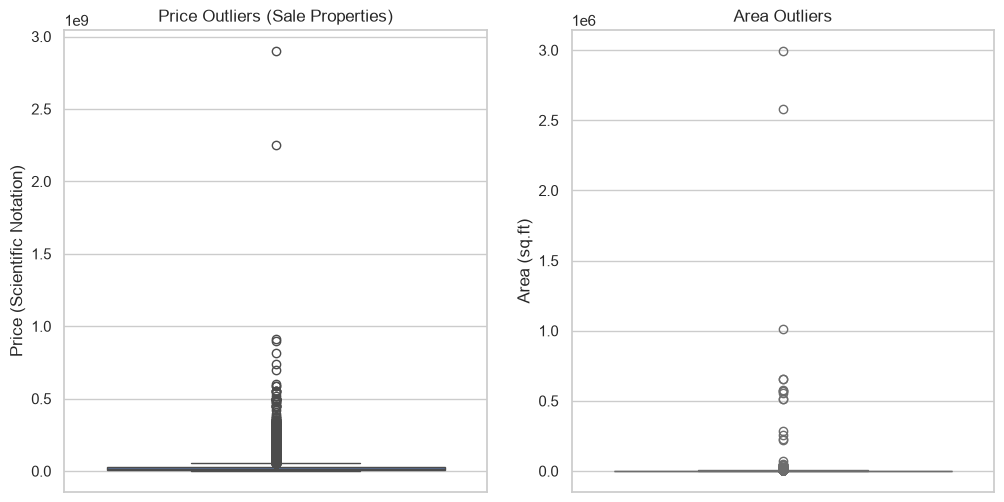

In [26]:
# Visualize area outliers
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
sns.boxplot(y=master_df["Price"])
plt.title("Price Outliers (Sale Properties)")
plt.ylabel("Price (Scientific Notation)")

plt.subplot(1, 2, 2)
sns.boxplot(y=master_df["Area"], color="salmon")
plt.title("Area Outliers")
plt.ylabel("Area (sq.ft)")
plt.show()

In [27]:
def upper_bound(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    upper_range = Q3 + (1.5*IQR)
    return upper_range

# Determine outlier thresholds
max_price = upper_bound(master_df, "Price")
max_area = upper_bound(master_df, "Area")

# Remove outliers above the calculated maximums
master_df = master_df[(master_df["Price"] <= max_price) & (master_df["Area"] <= max_area)]
# Set practical minimums to remove low-end noise
price_floor = 1000000
area_floor = 500

# Remove outliers below the minimum floors
master_df = master_df[((master_df["Price"] >= price_floor) & (master_df["Area"] >= area_floor))]

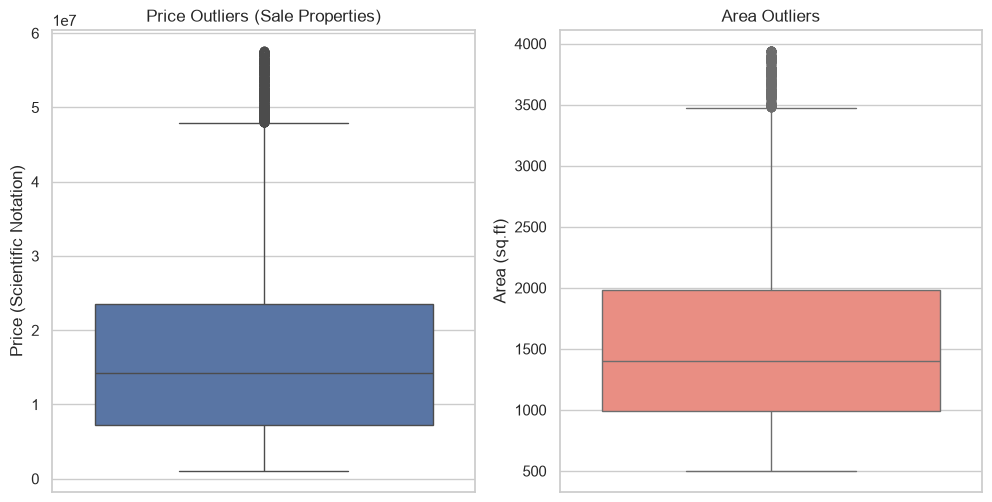

In [28]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12,6))

# Visualize price outliers
plt.subplot(1,2,1)
sns.boxplot(y=master_df["Price"])
plt.title("Price Outliers (Sale Properties)")
plt.ylabel("Price (Scientific Notation)")

# Visualize area outliers
plt.subplot(1, 2, 2)
sns.boxplot(y=master_df["Area"], color="salmon")
plt.title("Area Outliers")
plt.ylabel("Area (sq.ft)")

plt.show()

In [29]:
# Calculate Price Per Square Foot (PPSF) to normalize the valuation, 
master_df["ppsf"] = master_df["Price"] / master_df["Area"]

# Determine the 99th percentile thresholds to define the "Luxury" tier.
price_cap = master_df["Price"].quantile(0.99)
area_cap = master_df["Area"].quantile(0.99)

# Inspect the count of property types in the luxury tier.
# This helps confirm that these rows are legitimate market segments rather than just noise.
print("Luxury Properties")
print(master_df[(master_df["Area"] >= area_cap) | (master_df["Price"] >= price_cap)]["Property_Type"].value_counts())

# Feature Engineering: Create a binary flag ('Is_Luxury') for top-tier properties.
master_df['Is_Luxury'] = ((master_df["Area"] >= area_cap) | (master_df["Price"] >= price_cap)).astype(int)

# Filter out listings with an unrealistically low PPSF (< 1000).
# These are likely data entry errors or scraper artifacts rather than real property values.
master_df = master_df[~(master_df["ppsf"] < 1000)]

Luxury Properties
Property_Type
Residential Apartment        297
Independent House/Villa      123
Independent/Builder Floor    110
Name: count, dtype: int64


In [30]:
# 1. Define mapping dictionary to map respective values
ownership_mapping = {
    1: "Freehold",
    2: "Leasehold",
    3: "Co-operative",
    4: "Power of Attorney"
}

furnish_mapping = {
    1: "Furnished",
    2: "Unfurnished",
    4: "Semifurnished"
}
direction_mapping = {
    1: 'North',
    2: 'South',
    3: 'East',
    4: 'West',
    5: 'North-East',
    6: 'North-West',
    7: 'South-East',
    8: 'South-West'
}

age_mapping = {
    1: '1-5 Year Old',
    2: '5-10 Year Old',
    3: '10+ Year Old',
    5: 'Under Construction',
    6: '0-1 Year Old'
}
# 2. Map the values the column
master_df['Owntype'] = master_df['Owntype'].map(ownership_mapping)
master_df['Furnish'] = master_df['Furnish'].map(furnish_mapping)
master_df['Facing'] = master_df['Facing'].map(direction_mapping)
master_df['Age'] = master_df['Age'].map(age_mapping)

In [31]:
master_df.isnull().sum()

Property_Type              0
Owntype                    0
Bedroom_Num                0
Balcony_Num                0
Furnish                 5517
Facing                  6970
Age                        3
Floor_Num                  0
Total_Floor                0
Features                   0
Amenities                  0
Area                       0
Price                      0
Total_Landmark_Count       0
City                       0
LOCALITY_NAME              0
Sqft_per_room              0
ppsf                       0
Is_Luxury                  0
dtype: int64

In [32]:
master_df["Furnish"] = master_df["Furnish"].fillna("Unknown")
master_df["Facing"] = master_df["Facing"].fillna("Unknown")
master_df.dropna(subset=["Age"],inplace=True)

In [33]:
master_df["Total_Amenities"] = master_df["Amenities"].apply(lambda x: len(x.split(',')) if isinstance(x, str) else 0)
master_df = master_df.drop(columns=["Amenities", "Features"], errors="ignore")

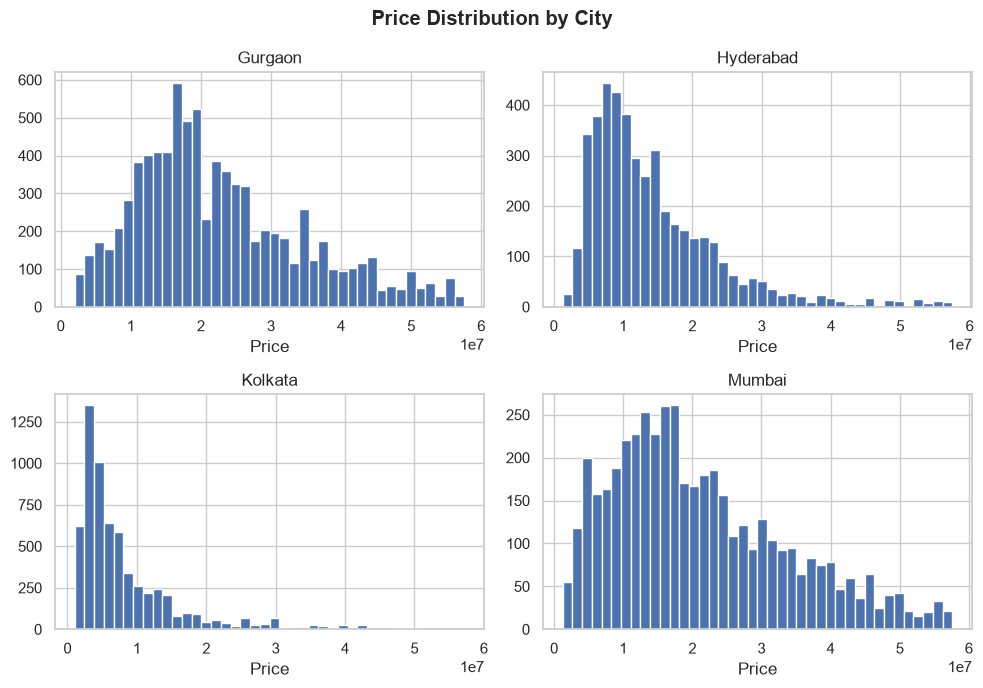

In [34]:
fig, axes = plt.subplots(2,2,figsize=(10,7))
axes = axes.flatten()

for ax, city in zip(axes,master_df["City"].unique()):
    ax.hist(x = master_df[master_df["City"] == city]["Price"],bins=40)
    ax.set_title(city)
    ax.set_xlabel("Price")

plt.suptitle("Price Distribution by City", fontweight="bold")
plt.tight_layout()
plt.show()

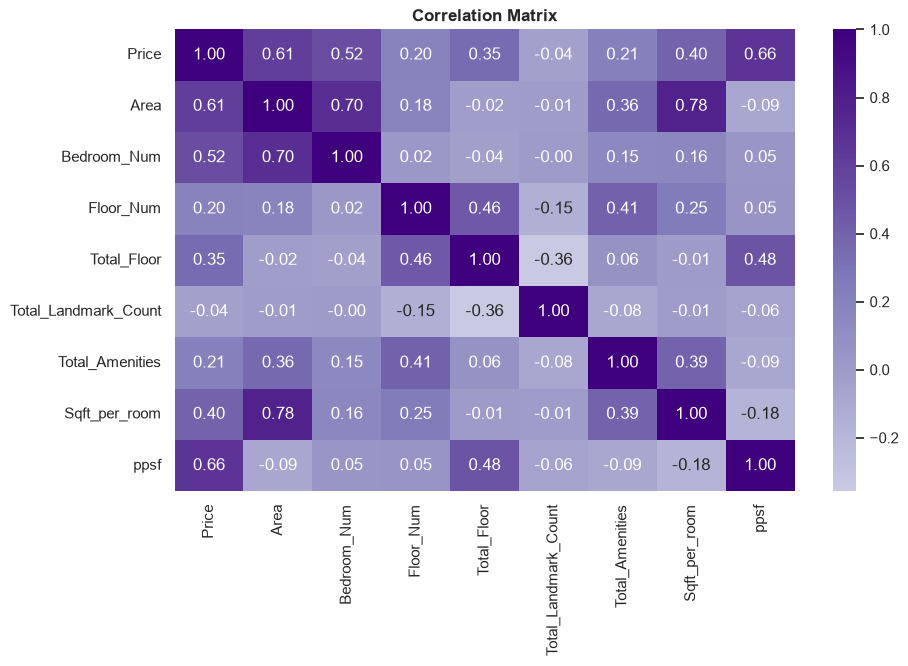

In [35]:
num_cols = ['Price', 'Area', 'Bedroom_Num', 'Floor_Num', 
            'Total_Floor', 'Total_Landmark_Count', 'Total_Amenities',"Sqft_per_room","ppsf"]
plt.figure(figsize=(10,6))
sns.heatmap(master_df[num_cols].corr(),annot=True,fmt=".2f",cmap="Purples",center=0)
plt.title("Correlation Matrix", fontweight="bold")
plt.show()

## Observation
Hence from correlation, area becomes most important feature

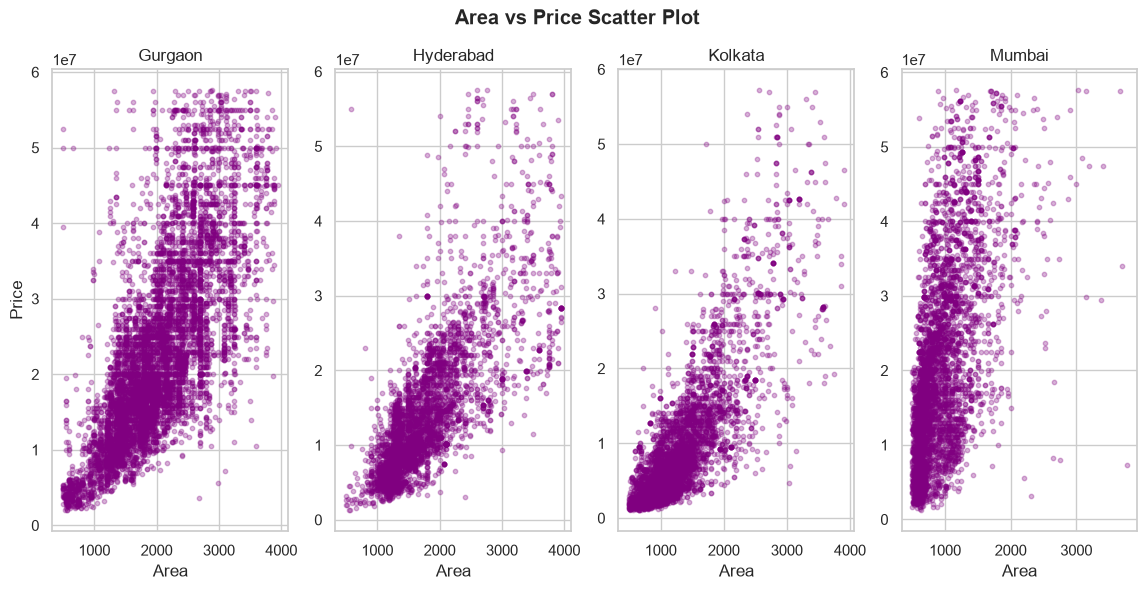

In [36]:
fig, axes = plt.subplots(1,4,figsize=(14,6))
axes = axes.flatten()
for ax, city in zip(axes, master_df["City"].unique()):
    city_df = master_df[master_df["City"] == city]
    ax.scatter(city_df["Area"],city_df["Price"],s=10,alpha=0.3,color='purple')
    ax.set_title(city)
    ax.set_xlabel("Area")
axes[0].set_ylabel("Price")
plt.suptitle("Area vs Price Scatter Plot",fontweight="bold")
plt.show()

In [37]:
city_df = master_df.pivot_table(values="Price",index="City",aggfunc=["median","mean","count","std"])
city_df.columns = ["_".join(i).capitalize() for i in city_df.columns]
city_df

,Median_price,Mean_price,Count_price,Std_price
City,,,,
Gurgaon,20000000.0,2.276441e+07,8327,1.204743e+07
Hyderabad,11600000.0,1.430034e+07,4465,9.463510e+06
Kolkata,5600000.0,8.456916e+06,6272,8.143784e+06
Mumbai,18100000.0,2.108221e+07,4659,1.266152e+07


In [38]:
valid_types = ['Residential Apartment', 
               'Independent/Builder Floor', 
               'Independent House/Villa']
master_df = master_df[master_df["Property_Type"].isin(valid_types)].copy()
master_df['Is_Freehold'] = (master_df['Owntype'] == 'Freehold').astype(int)
master_df = master_df[master_df["Bedroom_Num"] <= 5].copy()
master_df = master_df[master_df['Floor_Num'] <= master_df['Total_Floor']]
master_df["Log_Price"] = np.log1p(master_df["Price"])
master_df = master_df.reset_index(drop=True)

In [39]:
master_df.head()

,Property_Type,Owntype,Bedroom_Num,Balcony_Num,Furnish,Facing,Age,Floor_Num,Total_Floor,Area,Price,Total_Landmark_Count,City,LOCALITY_NAME,Sqft_per_room,ppsf,Is_Luxury,Total_Amenities,Is_Freehold,Log_Price
0,Residential Apartment,Freehold,4,4,Semifurnished,North,5-10 Year Old,14,26,3434.0,26300000.0,10,Gurgaon,Sector 84 Gurgaon,858.500000,7658.707047,0,19,1,17.085080
1,Residential Apartment,Freehold,4,3,Semifurnished,North,1-5 Year Old,7,29,2870.0,36000000.0,9,Gurgaon,Sector 81 Gurgaon,717.500000,12543.554007,0,25,1,17.399030
2,Residential Apartment,Freehold,3,3,Semifurnished,Unknown,1-5 Year Old,14,28,2802.0,38500000.0,8,Gurgaon,Sector 112 Gurgaon,934.000000,13740.185582,0,19,1,17.466169
3,Residential Apartment,Freehold,3,4,Semifurnished,South,1-5 Year Old,4,27,2290.0,19500000.0,14,Gurgaon,Sector 104 Gurgaon,763.333333,8515.283843,0,15,1,16.785925
4,Residential Apartment,Freehold,2,3,Unfurnished,East,0-1 Year Old,12,30,1400.0,16200000.0,13,Gurgaon,Sector 74 Gurgaon,700.000000,11571.428571,0,8,1,16.600522


# Data Modeling

In [40]:
num_features = ["Bedroom_Num","Floor_Num","Total_Floor","Area"]
cat_features = ["Furnish", "Age","Facing","Property_Type","City"]
bin_features = ["Is_Luxury","Is_Freehold"]
locality_feature = ["LOCALITY_NAME"]

X = master_df[num_features + cat_features + bin_features + locality_feature]
y = master_df["Log_Price"]

In [41]:
X.head()

,Bedroom_Num,Floor_Num,Total_Floor,Area,Furnish,Age,Facing,Property_Type,City,Is_Luxury,Is_Freehold,LOCALITY_NAME
0,4,14,26,3434.0,Semifurnished,5-10 Year Old,North,Residential Apartment,Gurgaon,0,1,Sector 84 Gurgaon
1,4,7,29,2870.0,Semifurnished,1-5 Year Old,North,Residential Apartment,Gurgaon,0,1,Sector 81 Gurgaon
2,3,14,28,2802.0,Semifurnished,1-5 Year Old,Unknown,Residential Apartment,Gurgaon,0,1,Sector 112 Gurgaon
3,3,4,27,2290.0,Semifurnished,1-5 Year Old,South,Residential Apartment,Gurgaon,0,1,Sector 104 Gurgaon
4,2,12,30,1400.0,Unfurnished,0-1 Year Old,East,Residential Apartment,Gurgaon,0,1,Sector 74 Gurgaon


In [42]:

# Train, Test and Validation Split of Data
X_train, X_, y_train, y_ = train_test_split(X,y,test_size=0.4,random_state=42)
X_test, X_cv, y_test, y_cv = train_test_split(X_,y_,test_size=0.5,random_state=42)

xgb_preprocessor = ColumnTransformer(transformers = [
    ("num_features","passthrough",num_features),
    ("cat_features", OneHotEncoder(handle_unknown="ignore"),cat_features),
    ("locality",TargetEncoder(smooth="auto"),locality_feature),
    ("bin_features","passthrough",bin_features)
])

In [43]:
xgb_model = XGBRegressor(n_estimators=10000, learning_rate=0.01, max_depth=5, n_jobs=-1,random_state=42,early_stopping_rounds=50,
                         reg_lambda=3,subsample=0.7,colsample_bytree=0.7,min_child_weight=5,reg_alpha=3)

In [44]:
X_train_transformed = xgb_preprocessor.fit_transform(X_train,y_train)
X_cv_transformed = xgb_preprocessor.transform(X_cv)

xgb_model.fit(X_train_transformed,y_train,eval_set=[(X_cv_transformed,y_cv)],verbose=1000)
print(f"Best Iteration: {xgb_model.best_iteration}")

[0]	validation_0-rmse:0.81277
[1000]	validation_0-rmse:0.26373
[2000]	validation_0-rmse:0.25586
[3000]	validation_0-rmse:0.25264
[4000]	validation_0-rmse:0.25096
[5000]	validation_0-rmse:0.24985
[5631]	validation_0-rmse:0.24935
Best Iteration: 5581


In [47]:
X_test_transformed = xgb_preprocessor.transform(X_test)
yhat_train = xgb_model.predict(X_train_transformed)
yhat_cv = xgb_model.predict(X_cv_transformed)
yhat_test = xgb_model.predict(X_test_transformed)

print("\n" + "="*45)
print("XGBoost— FINAL RESULTS")
print("="*45)
print(f"Train R2:       {r2_score(y_train, yhat_train)*100:.2f}%")
print(f"CV R2:          {r2_score(y_cv,yhat_cv)   *100:.2f}%")
print(f"Test R2:        {r2_score(y_test,yhat_test) *100:.2f}%")
print(f"Gap:            {(r2_score(y_train, yhat_train) - r2_score(y_test,yhat_test))*100:.2f}%")
print(f"Train MAE %:    {f"{mean_absolute_percentage_error(y_train, yhat_train) * 100:.2f}%"}")


XGBoost— FINAL RESULTS
Train R2:       93.45%
CV R2:          90.66%
Test R2:        91.14%
Gap:            2.31%
Train MAE %:    0.95%


In [50]:
xgb_model

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.7
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [52]:
import pickle

model_bundle = {
    "preprocessor": xgb_preprocessor,
    "model": xgb_model
}

with open("model/real_estate_xgb.pkl", "wb") as f:
    pickle.dump(model_bundle, f)

In [53]:
X_test.to_csv("check.csv")

In [54]:
X.columns

Index(['Bedroom_Num', 'Floor_Num', 'Total_Floor', 'Area', 'Furnish', 'Age',
       'Facing', 'Property_Type', 'City', 'Is_Luxury', 'Is_Freehold',
       'LOCALITY_NAME'],
      dtype='str')

In [73]:
X["Is_Freehold"].unique()

array([1, 0])